# Software engineering benchmark tasks

A first pass at the text of the public benchmark tasks. Run all cells from top to bottom. The notebook reads the local snapshots listed in `data/sources.json`.

The main charts cover **1,625 shortlisted records plus 186 E2E-SWE tasks**. The two historical snapshots have their own comparison table. Pro V2 Hard is a subset of the 642 Pro V2 records. FrontierCode 2.0 is outside this corpus because its full task set is private.

In [1]:
from collections import Counter
import hashlib
import json
from pathlib import Path
import re
import tomllib

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
RAW = ROOT / "data" / "raw"
SOURCES = json.loads((ROOT / "data" / "sources.json").read_text(encoding="utf-8"))

## 1. Load and validate the corpus

The comparison uses the primary instruction: Harbor instructions, the Atlas Q&A prompt, or the SWE-bench problem statement. Pro requirements and interface fields, and Verified hints, are recorded separately from that main text. Language, repository, and category are taken from the sources when available.

In [2]:
def clean_text(value):
    return value.strip() if isinstance(value, str) else ""


def first_text(*values):
    return next((text for value in values if (text := clean_text(value))), "")


def task_row(source, task_id, prompt, *, language="", repository="", category="", extra=""):
    return {
        "benchmark": source["name"],
        "cohort": source["cohort"],
        "task_id": clean_text(task_id),
        "prompt": clean_text(prompt),
        "language": clean_text(language),
        "repository": clean_text(repository),
        "source_category": clean_text(category),
        "supplemental_text": clean_text(extra),
    }


def read_tasks(source):
    location = RAW / source["location"]
    if not location.exists():
        raise FileNotFoundError(f"Missing local data for {source['name']}: {location}")
    kind = source["format"]
    if kind == "harbor":
        rows = []
        for instruction in sorted(location.glob("*/instruction.md")):
            config = tomllib.loads(instruction.with_name("task.toml").read_text(encoding="utf-8"))
            meta = config.get("metadata", {})
            rows.append(task_row(
                source, instruction.parent.name, instruction.read_text(encoding="utf-8"),
                language=first_text(meta.get("language"), meta.get("programming_language")),
                repository=first_text(meta.get("repository_url"), meta.get("repository"), meta.get("repo")),
                category=meta.get("category", ""),
            ))
        return pd.DataFrame(rows)

    records = pd.read_csv(location) if kind == "atlas_qa" else pd.read_parquet(location)
    rows = []
    for row in records.to_dict("records"):
        if kind == "atlas_qa":
            rows.append(task_row(
                source, row["task_id"], row["prompt"], language=row["language"],
                repository=row["repository_url"], category=row["category"],
            ))
        elif kind == "deep":
            rows.append(task_row(
                source, row["task_id"], row["instruction"], language=row["language"],
                repository=row["repository_url"], category=row["category"],
            ))
        else:
            extra = "\n\n".join(
                clean_text(row.get(field)) for field in ("requirements", "interface", "hints_text")
                if clean_text(row.get(field))
            )
            rows.append(task_row(
                source, row["instance_id"], row["problem_statement"],
                language="Python" if kind == "verified" else row.get("repo_language"),
                repository=row["repo"], extra=extra,
            ))
    return pd.DataFrame(rows)


snapshots = {}
for source in SOURCES:
    frame = read_tasks(source)
    assert len(frame) == source["count"], f"{source['name']}: unexpected task count {len(frame)}"
    assert frame["task_id"].ne("").all() and frame["task_id"].is_unique, source["name"]
    assert frame["prompt"].ne("").all(), f"{source['name']}: empty primary instruction"
    snapshots[source["name"]] = frame

pro_v2 = snapshots["SWE-bench Pro V2"].set_index("task_id")
hard = snapshots["SWE-bench Pro V2 Hard"].set_index("task_id")
assert hard["prompt"].equals(pro_v2.loc[hard.index, "prompt"])

tasks = pd.concat(
    [frame for name, frame in snapshots.items() if name != "SWE-bench Pro V2 Hard"],
    ignore_index=True,
)
tasks["pro_v2_hard"] = tasks["benchmark"].eq("SWE-bench Pro V2") & tasks["task_id"].isin(hard.index)
corpus = tasks.loc[tasks["cohort"].isin(["current", "extension"])].copy()
display(pd.DataFrame(SOURCES)[["name", "count", "cohort", "source", "revision"]])

,name,count,cohort,source,revision
0,Terminal-Bench 4.1,66,current,https://huggingface.co/datasets/harborframewor...,c113b65be3040328e8d56a1361d90556d39ede4d
1,DeepSWE 1.1,113,current,https://huggingface.co/datasets/luolc/deep-swe...,1d44e226ccb93ebea6d8ff91dc0091fbec6494a5
2,SWE-bench Pro V2,642,current,https://huggingface.co/datasets/ScaleAI/SWE-be...,2d52cb3df914a3fcf80c7f66738b3a88ae37fc50
3,SWE Atlas Q&A,124,current,https://huggingface.co/datasets/ScaleAI/SWE-At...,fcdc7f8a9814e4c678c9a66d938d57afd67bc335
4,SWE Atlas Test Writing,90,current,https://github.com/scaleapi/SWE-Atlas,b3cdddf44414c0ccca50c6e89fe978bb4d844d26
5,SWE Atlas Refactoring,70,current,https://github.com/scaleapi/SWE-Atlas,b3cdddf44414c0ccca50c6e89fe978bb4d844d26
6,SWE-Marathon 1.1,20,current,https://github.com/abundant-ai/swe-marathon,7bce7b29e1f2413633eb5ed6eb10dc2efb036712
7,SWE-bench Verified,500,current,https://huggingface.co/datasets/princeton-nlp/...,c104f840cc67f8b6eec6f759ebc8b2693d585d4a
8,E2E-SWE,186,extension,https://github.com/facebookresearch/E2E-SWE,e696e96cb0f024d3231a9c1a41527c016d872f36
9,Terminal-Bench 4.0,66,historical,https://huggingface.co/datasets/harborframewor...,6637b03798cf840c3917694a6df5d8572cfae1d6


## 2. Prompt size and structure

Word counts are regex estimates over the original text. They include identifiers and code visible in the instruction. Markup checks are descriptive, and repository coverage reflects only supplied metadata.

In [3]:
word_re = re.compile(r"\b[\w]+(?:['’-][\w]+)*\b")

corpus["characters"] = corpus["prompt"].str.len()
corpus["words"] = corpus["prompt"].map(lambda text: len(word_re.findall(text)))
corpus["lines"] = corpus["prompt"].map(lambda text: len(text.splitlines()))
corpus["markdown_heading"] = corpus["prompt"].str.contains(r"(?m)^\s{0,3}#{1,6}\s")
corpus["fenced_code"] = corpus["prompt"].str.contains(r"(?m)^\s*(?:\x60{3}|~{3})")
corpus["repo_reported"] = corpus["repository"].ne("")
corpus["has_supplement"] = corpus["supplemental_text"].ne("")
by_benchmark = corpus.groupby("benchmark", sort=False)

summary = by_benchmark.agg(
    tasks=("task_id", "size"),
    median_words=("words", "median"),
    p90_words=("words", lambda counts: counts.quantile(.9)),
    median_lines=("lines", "median"),
    heading_pct=("markdown_heading", lambda values: values.mean() * 100),
    code_fence_pct=("fenced_code", lambda values: values.mean() * 100),
    repo_reported_pct=("repo_reported", lambda values: values.mean() * 100),
    supplement_pct=("has_supplement", lambda values: values.mean() * 100),
)
display(summary.round(1))

,tasks,median_words,p90_words,median_lines,heading_pct,code_fence_pct,repo_reported_pct,supplement_pct
benchmark,,,,,,,,
Terminal-Bench 4.1,66,235.0,503.5,15.5,1.5,30.3,0.0,0.0
DeepSWE 1.1,113,294.0,480.4,15.0,15.9,2.7,100.0,0.0
SWE-bench Pro V2,642,138.5,238.0,11.5,93.6,3.9,100.0,100.0
SWE Atlas Q&A,124,203.5,331.8,1.0,0.0,0.0,100.0,0.0
SWE Atlas Test Writing,90,625.0,1257.7,118.0,88.9,100.0,100.0,0.0
SWE Atlas Refactoring,70,384.0,890.7,31.0,8.6,0.0,0.0,0.0
SWE-Marathon 1.1,20,433.0,2545.2,49.5,85.0,40.0,0.0,0.0
SWE-bench Verified,500,164.0,448.2,27.0,31.2,46.6,100.0,67.0
E2E-SWE,186,2219.0,3698.0,273.0,100.0,87.6,0.0,0.0


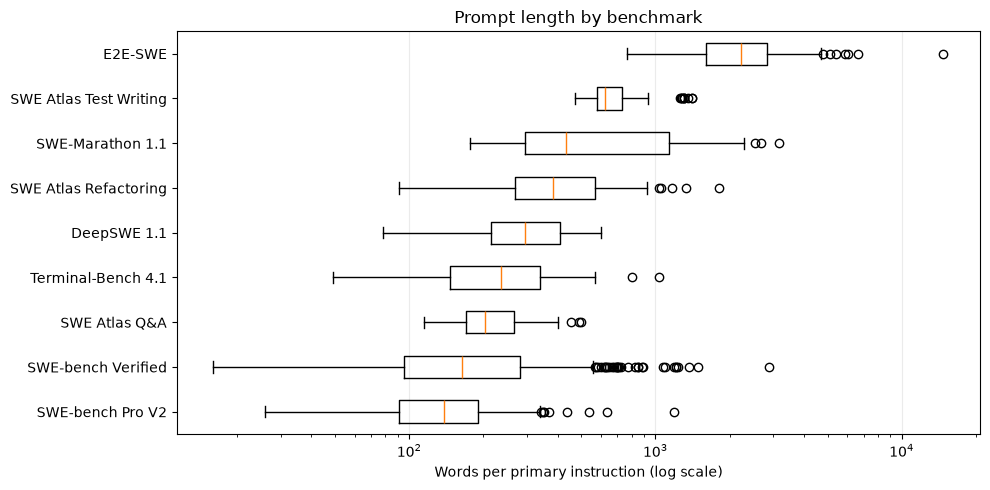

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
labels = list(summary.sort_values("median_words").index)
series = [corpus.loc[corpus["benchmark"].eq(label), "words"] for label in labels]
ax.boxplot(series, orientation="horizontal", tick_labels=labels, showfliers=True)
ax.set_xscale("log")
ax.set_xlabel("Words per primary instruction (log scale)")
ax.set_title("Prompt length by benchmark")
ax.grid(axis="x", alpha=.25)
fig.tight_layout()
plt.show()

## 3. Shared vocabulary and reported language

The term table counts how many documents mention a word at least once. It drops a small stop list and removes fenced blocks before tokenizing. Language names share a normalized spelling, and missing language values remain visible.

In [5]:
stop_words = set("""
about after again also and are before being both can could each from had have has how into its
make may must new not only other our out over should some than that the their them then there
these they this through under use used using want was were what when where which while will with
would you your all any for one two based same such ensure need should
""".split())
fenced_block = re.compile(r"(?ms)^\s*(?:\x60{3}|~{3})[^\n]*\n.*?^\s*(?:\x60{3}|~{3})[^\n]*")


def document_terms(text):
    tokens = word_re.findall(fenced_block.sub(" ", text).lower())
    return {token for token in tokens if len(token) >= 3 and token.isalpha() and token not in stop_words}


term_rows = []
for benchmark, group in by_benchmark:
    counts = Counter(term for text in group["prompt"] for term in document_terms(text))
    top = sorted(counts.items(), key=lambda item: (-item[1], item[0]))[:8]
    term_rows.append({
        "benchmark": benchmark,
        "top terms (% of prompts)": ", ".join(f"{term} {count / len(group):.0%}" for term, count in top),
    })
display(pd.DataFrame(term_rows).set_index("benchmark"))

languages = corpus["language"].str.lower().replace({
    "": "unreported", "js": "javascript", "ts": "typescript", "golang": "go",
})
language_counts = pd.crosstab(corpus["benchmark"], languages)
display(language_counts.reindex(summary.index).loc[:, language_counts.sum().sort_values(ascending=False).index])

,top terms (% of prompts)
benchmark,
Terminal-Bench 4.1,"cheat 100%, complete 100%, guid 100%, hints 10..."
DeepSWE 1.1,"branch 100%, commit 100%, done 100%, everythin..."
SWE-bench Pro V2,"description 85%, title 80%, expected 54%, beha..."
SWE Atlas Q&A,"but 81%, temporary 77%, understand 77%, reposi..."
SWE Atlas Test Writing,"acceptance 100%, according 100%, added 100%, a..."
SWE Atlas Refactoring,"already 100%, answer 100%, care 100%, changes ..."
SWE-Marathon 1.1,"app 100%, bash 100%, check 100%, hours 100%, m..."
SWE-bench Verified,"description 58%, https 41%, com 37%, but 35%, ..."
E2E-SWE,"value 94%, default 92%, build 90%, every 89%, ..."


language,python,go,unreported,javascript,typescript,c,java,c++,rust,swift,c#,kotlin
benchmark,,,,,,,,,,,,
Terminal-Bench 4.1,0,0,66,0,0,0,0,0,0,0,0,0
DeepSWE 1.1,34,34,0,5,35,0,0,0,5,0,0,0
SWE-bench Pro V2,237,256,0,145,4,0,0,0,0,0,0,0
SWE Atlas Q&A,29,38,0,0,31,26,0,0,0,0,0,0
SWE Atlas Test Writing,0,0,90,0,0,0,0,0,0,0,0,0
SWE Atlas Refactoring,0,0,70,0,0,0,0,0,0,0,0,0
SWE-Marathon 1.1,0,0,20,0,0,0,0,0,0,0,0,0
SWE-bench Verified,500,0,0,0,0,0,0,0,0,0,0,0
E2E-SWE,103,14,0,6,6,9,15,15,4,8,4,2


## 4. Version changes and exact text reuse

Version deltas match exact source IDs within a benchmark family. The duplicate check compares prompts after lowercasing and collapsing whitespace. A text match is a lead for review rather than proof that two tasks use the same environment or verifier.

In [6]:
def compare_versions(old_name, new_name):
    old = snapshots[old_name].set_index("task_id")["prompt"]
    new = snapshots[new_name].set_index("task_id")["prompt"]
    common = old.index.intersection(new.index)
    return {
        "comparison": f"{old_name} → {new_name}",
        "matched_ids": len(common),
        "rewritten_primary_text": int(old.loc[common].ne(new.loc[common]).sum()),
        "old_only": len(old.index.difference(new.index)),
        "new_only": len(new.index.difference(old.index)),
    }


version_changes = pd.DataFrame([
    compare_versions("Terminal-Bench 4.0", "Terminal-Bench 4.1"),
    compare_versions("SWE-bench Pro V1", "SWE-bench Pro V2"),
]).set_index("comparison")
display(version_changes)

corpus["prompt_hash"] = corpus["prompt"].map(
    lambda text: hashlib.sha256(" ".join(text.casefold().split()).encode()).hexdigest()
)
reused_text = (
    corpus.groupby("prompt_hash", as_index=False)
    .agg(task_records=("task_id", "size"), benchmarks=("benchmark", "nunique"))
    .query("task_records > 1")
)
print(f"{len(reused_text)} repeated prompt texts in the main corpus, "
      f"including {reused_text['benchmarks'].gt(1).sum()} that span benchmarks.")

,matched_ids,rewritten_primary_text,old_only,new_only
comparison,,,,
Terminal-Bench 4.0 → Terminal-Bench 4.1,66,0,0,0
SWE-bench Pro V1 → SWE-bench Pro V2,642,529,89,0


0 repeated prompt texts in the main corpus, including 0 that span benchmarks.


## 5. Inspect task records

The table omits the prompt by default. Change the selected benchmark or inspect the `prompt` column in `corpus` when you want to read the actual instructions. New analyses can build on `corpus` for the main set, or `snapshots` for source versions.

In [7]:
selected = "DeepSWE 1.1"
preview = (
    corpus.loc[corpus["benchmark"].eq(selected)]
    .sort_values(["words", "task_id"], ascending=[False, True])
    [["task_id", "language", "repository", "source_category", "words", "lines"]]
)
display(preview.head(10))

,task_id,language,repository,source_category,words,lines
73,arcane-drift-detection-baselines,go,https://github.com/getarcaneapp/arcane.git,feature_request,603,25
118,kombu-virtual-queue-dead-lettering,python,https://github.com/celery/kombu,feature_request,546,23
117,kombu-single-active-consumer-priority,python,https://github.com/celery/kombu,feature_request,544,23
92,etree-xml-diff-patch,go,https://github.com/beevik/etree,feature_request,532,19
158,superjson-error-stack-serialization,typescript,https://github.com/flightcontrolhq/superjson.git,feature_request,529,29
79,boa-hierarchical-evaluation-cancellation,rust,https://github.com/boa-dev/boa,feature_request,522,52
172,vitest-duration-sharding,typescript,https://github.com/vitest-dev/vitest.git,feature_request,514,93
174,wasmi-trap-coredumps,rust,https://github.com/wasmi-labs/wasmi,feature_request,510,18
170,updo-policy-alerting,go,https://github.com/Owloops/updo,feature_request,501,78
147,pwntools-tube-multiplexing,python,https://github.com/Gallopsled/pwntools,feature_request,500,21


## 6. Task requests, verifier design, and grading

This section joins every local prompt to grading evidence on **benchmark + task ID**. It includes historical snapshots for paired comparison and verifies that the main corpus still counts Pro V2 Hard once.

- **Task features** extract action, requirement, and prohibition clauses, multi-label intent signals, and deliverable or path mentions.
- **Verifier features** inventory text artifacts, show declared workspace boundaries, and record check signals with source locations or a benchmark protocol.
- **Grading features** distinguish configured test groups, rubric criteria, score channels, and the published decision rule. A numeric reward file does not establish the meaning of its values.

All features come from static text and metadata. Source rules and locally observed signals remain distinct. Word matches do not measure whether a test actually covers a requirement. Unavailable task-level metadata stays missing, never imputed as zero.

SWE Atlas Q&A pairs use the Hugging Face rubric that ships with its prompts. The drilldown exposes the separate pinned GitHub rubric and labels whether criterion text differs. GitHub verifier files describe that GitHub snapshot.

Sources: [Harbor verifier contract](https://docs.harborframework.com/tasks/verifier), [DeepSWE](https://github.com/datacurve-ai/deep-swe), [SWE-bench Verified](https://openai.com/index/introducing-swe-bench-verified/), [SWE-bench Pro V2](https://labs.scale.com/blog/swe-bench-pro-v2), [SWE Atlas](https://labs.scale.com/papers/sweatlas), [SWE-Marathon](https://github.com/abundant-ai/swe-marathon), [E2E-SWE](https://github.com/facebookresearch/E2E-SWE).

In [8]:
from task_verifier_features import (
    CHECK_RULES, DELIVERABLES, INTENTS,
    task_clauses, task_intents, task_deliverables,
    verifier_inventory, verifier_boundary, verifier_checks,
    grade_test_groups, grade_rubrics, grade_contract,
    build_feature_tables, inspect_task,
)

MIN_SIMILARITY = 0.15
task_features, task_evidence = build_feature_tables(tasks, SOURCES, RAW, MIN_SIMILARITY)
feature_scope = task_features.reset_index()
main_order = list(corpus["benchmark"].drop_duplicates())
main_features = feature_scope.loc[feature_scope["cohort"].isin(["current", "extension"])].copy()

assert len(main_features) == len(corpus)
coverage = feature_scope.groupby("benchmark", sort=False).agg(
    tasks=("task_id", "size"),
    task_test_tree=("file_evidence", "sum"),
    entrypoint_text=("verifier_entrypoint_text", "sum"),
    test_patch=("test_patch_evidence", "sum"),
    f2p_list=("f2p_count", "count"),
    p2p_list=("p2p_count", "count"),
    rubric=("rubric_criteria", "count"),
    prompt_to_grader_pairable=("pair_rate", "count"),
)
display(coverage)
qa_versions = main_features.loc[main_features["benchmark"].eq("SWE Atlas Q&A"), "rubric_variant"]
display(qa_versions.fillna("Unavailable").value_counts().rename("SWE Atlas Q&A tasks"))

,tasks,task_test_tree,entrypoint_text,test_patch,f2p_list,p2p_list,rubric,prompt_to_grader_pairable
benchmark,,,,,,,,
Terminal-Bench 4.1,66,66,66,0,0,0,0,56
DeepSWE 1.1,113,0,113,113,113,113,0,113
SWE-bench Pro V2,642,0,0,642,642,642,0,642
SWE Atlas Q&A,124,124,124,0,0,0,124,120
SWE Atlas Test Writing,90,90,90,0,0,0,90,90
SWE Atlas Refactoring,70,70,70,0,0,0,70,70
SWE-Marathon 1.1,20,20,20,0,0,0,0,14
SWE-bench Verified,500,0,0,500,500,500,0,500
E2E-SWE,186,186,186,0,0,0,0,156


rubric_variant
Different criterion text    102
Same criterion text          22
Name: SWE Atlas Q&A tasks, dtype: int64

### Task requests and deliverables

Cells show the percent of tasks in each benchmark with each signal. A task can appear under several labels. Context mentions can trigger these text signals. They are searchable features, with the matched clauses available in the drilldown.

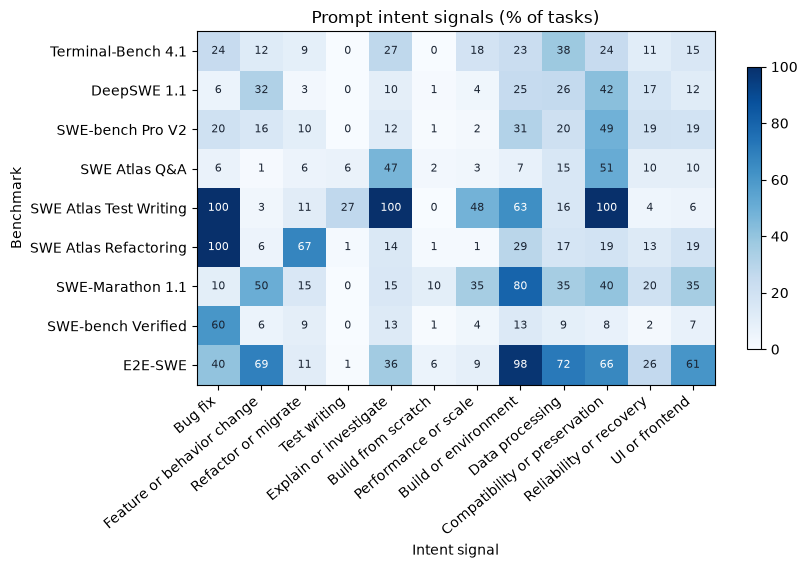

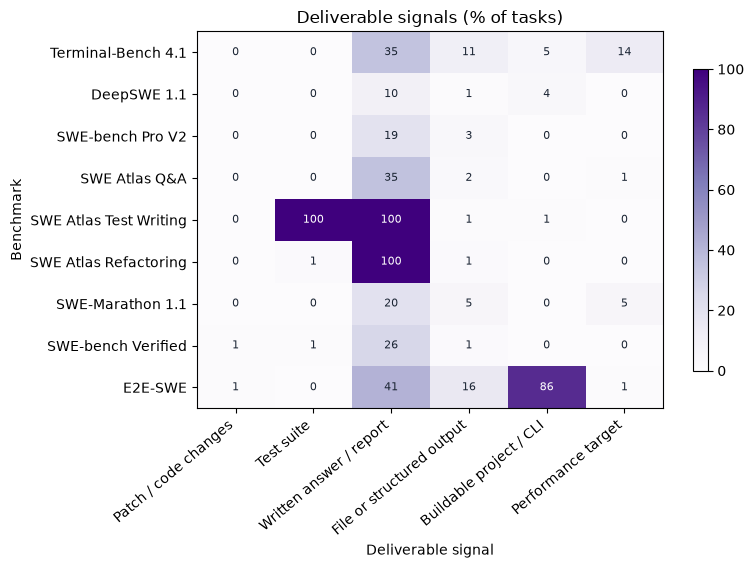

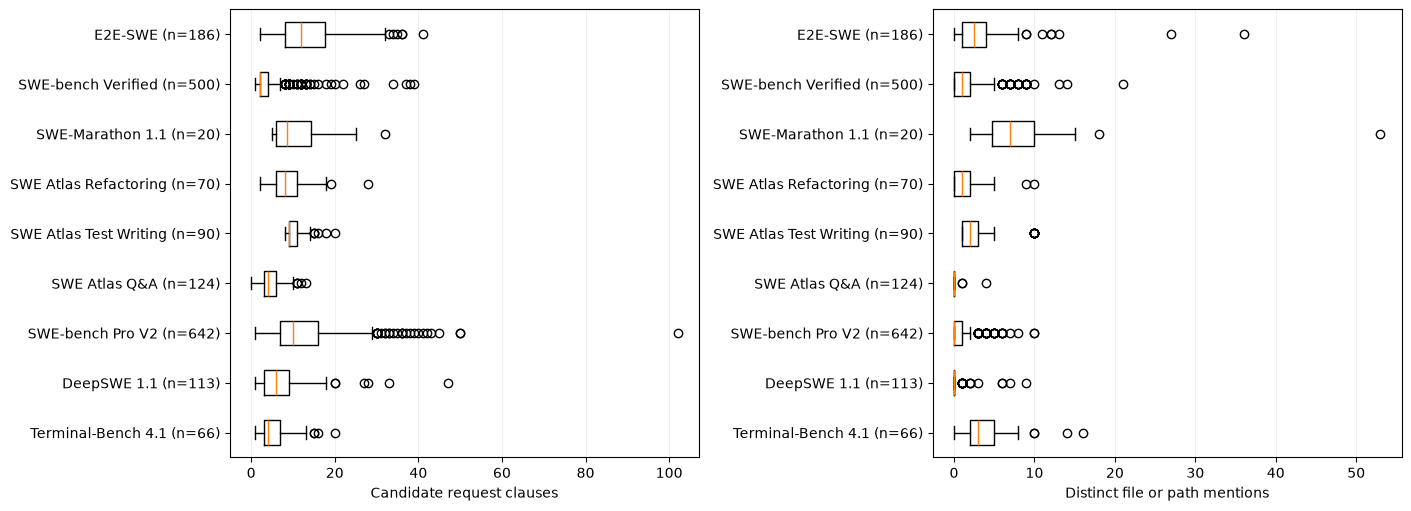

In [9]:
def prevalence_table(data, field, labels):
    indicators = pd.DataFrame(
        {label: data[field].map(lambda values: label in values) for label in labels},
        index=data.index,
    )
    return indicators.groupby(data["benchmark"], sort=False).mean().reindex(main_order).mul(100)


def heatmap(table, title, xlabel, ylabel="Benchmark", cmap="Blues", vmax=100):
    fig, ax = plt.subplots(figsize=(max(8, 0.72 * len(table.columns)), 2 + 0.42 * len(table)))
    values = table.astype(float).to_numpy()
    chart = ax.imshow(values, cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(table.columns)), table.columns, rotation=40, ha="right")
    ax.set_yticks(range(len(table)), table.index)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    for i, row in enumerate(values):
        for j, value in enumerate(row):
            if pd.notna(value):
                ax.text(j, i, f"{value:.0f}", ha="center", va="center",
                        color="white" if value > .62 * vmax else "#1a2433", fontsize=8)
    fig.colorbar(chart, ax=ax, shrink=.8)
    fig.tight_layout()
    plt.show()


intent_rates = prevalence_table(main_features, "intents", INTENTS)
deliverable_rates = prevalence_table(main_features, "deliverable_signals", DELIVERABLES)
heatmap(intent_rates, "Prompt intent signals (% of tasks)", "Intent signal")
heatmap(deliverable_rates, "Deliverable signals (% of tasks)", "Deliverable signal", cmap="Purples")

def by_benchmark_box(ax, feature, label, scale=None):
    groups = [
        main_features.loc[main_features["benchmark"].eq(name), feature].dropna()
        for name in main_order
    ]
    labels = [f"{name} (n={len(group)})" for name, group in zip(main_order, groups) if len(group)]
    if labels:
        ax.boxplot([group.to_numpy() for group in groups if len(group)],
                   orientation="horizontal", tick_labels=labels)
    ax.set_xlabel(label)
    if scale:
        ax.set_xscale(scale)
    ax.grid(axis="x", alpha=.2)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
by_benchmark_box(axes[0], "request_clauses", "Candidate request clauses")
by_benchmark_box(axes[1], "explicit_paths", "Distinct file or path mentions")
plt.show()

### Verifier design and grading

Check signals are multilabel. The workspace chart uses the task’s Harbor environment configuration, the Harbor default, or the benchmark’s documented workspace policy. A tests Dockerfile is packaging evidence and does not set isolation by itself. Test list sizes count configured entries, and rubric sizes count published criterion records. The boxplots show only tasks with a value and label the denominator.

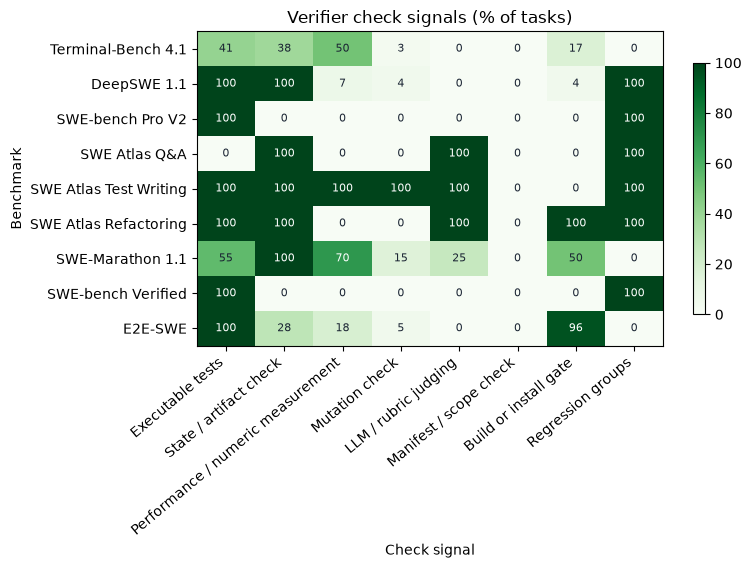

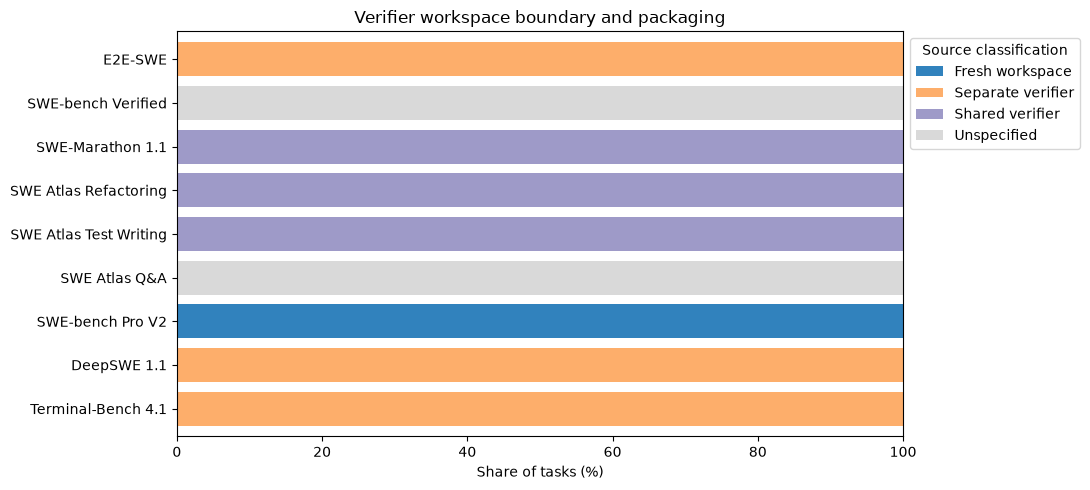

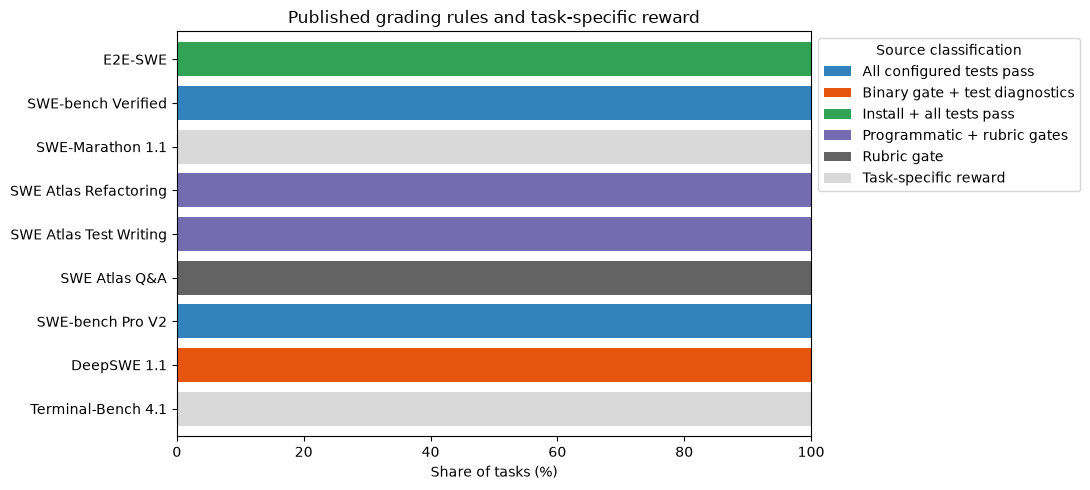

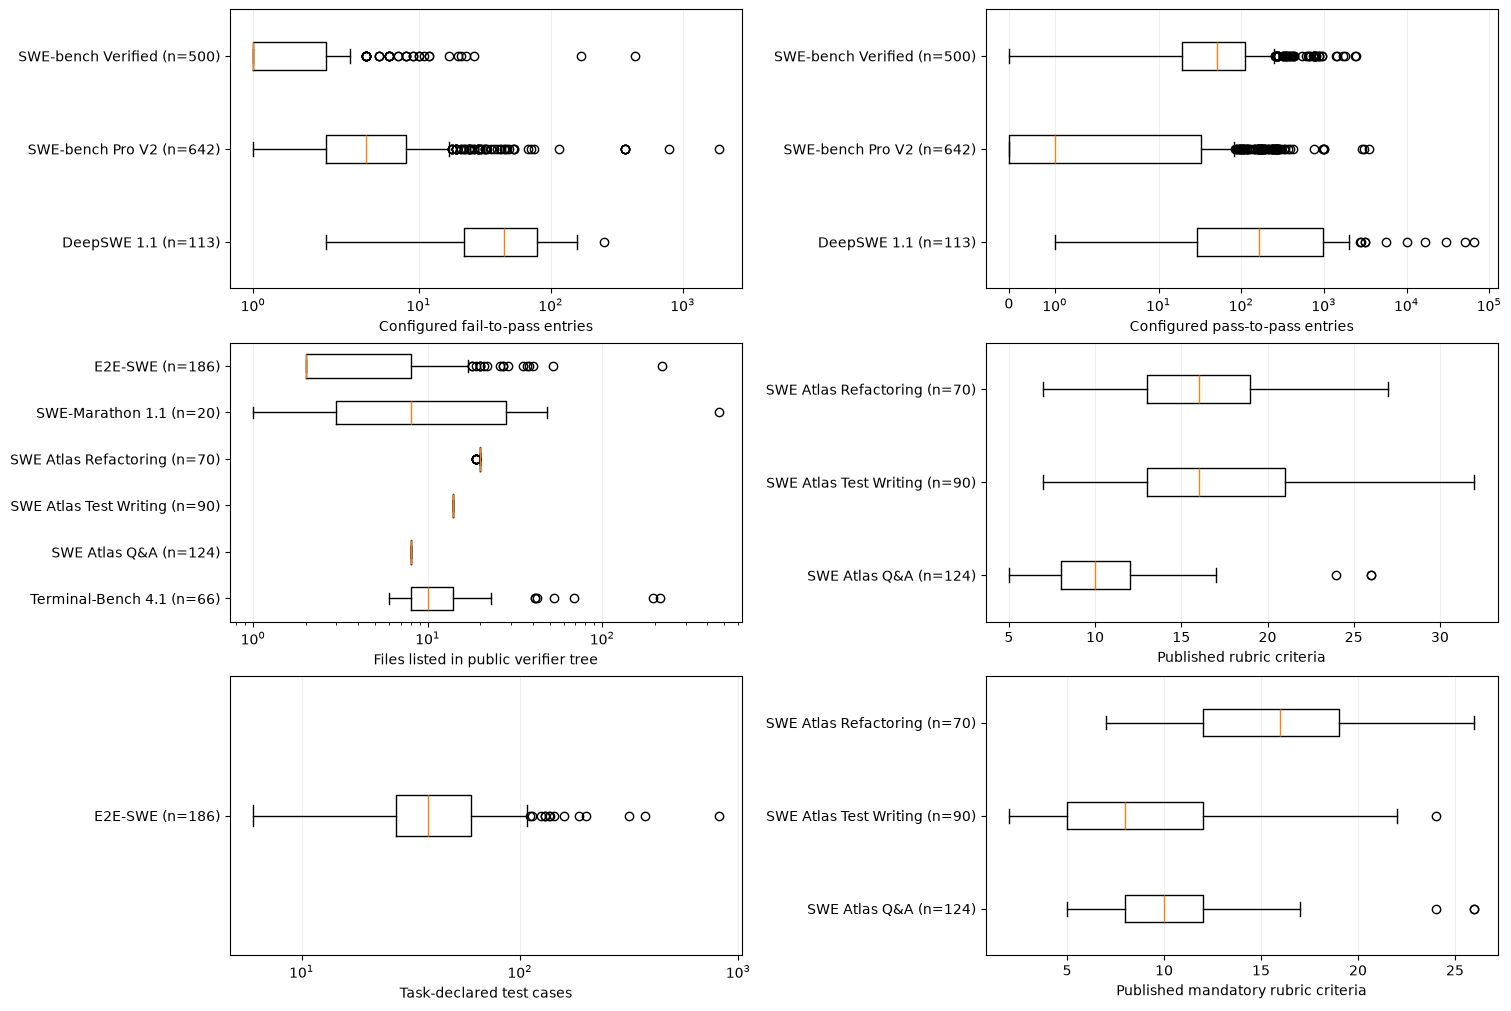

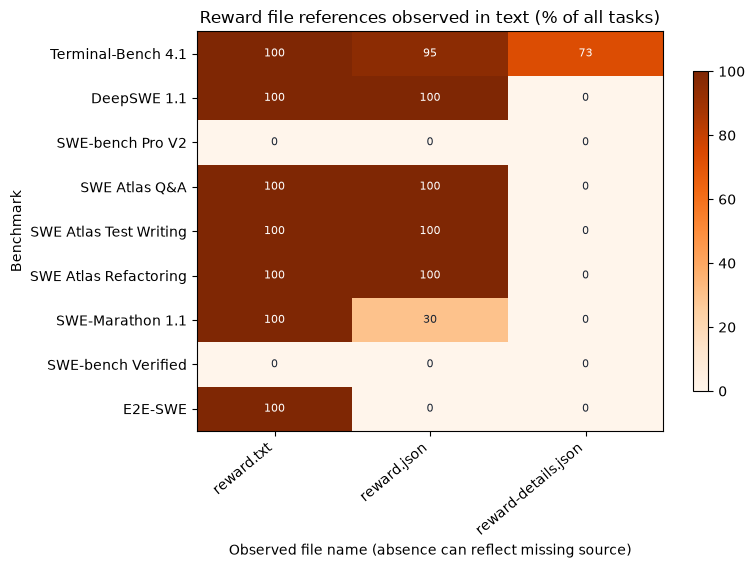

In [10]:
check_rates = prevalence_table(main_features, "check_signals", CHECK_RULES)
heatmap(check_rates, "Verifier check signals (% of tasks)", "Check signal", cmap="Greens")

boundary_mix = pd.crosstab(main_features["benchmark"], main_features["boundary"]).reindex(main_order)
grade_mix = pd.crosstab(main_features["benchmark"], main_features["grading_family"]).reindex(main_order)
for table, title in [
    (boundary_mix, "Verifier workspace boundary and packaging"),
    (grade_mix, "Published grading rules and task-specific reward"),
]:
    share = table.div(table.sum(axis=1), axis=0).mul(100)
    ax = share.plot.barh(stacked=True, figsize=(11, 5), width=.78, cmap="tab20c")
    ax.set(title=title, xlabel="Share of tasks (%)", ylabel="")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), title="Source classification")
    ax.figure.tight_layout()
    plt.show()

fig, axes = plt.subplots(3, 2, figsize=(15, 10), layout="constrained")
for ax, feature, label, scale in [
    (axes[0, 0], "f2p_count", "Configured fail-to-pass entries", "symlog"),
    (axes[0, 1], "p2p_count", "Configured pass-to-pass entries", "symlog"),
    (axes[1, 0], "verifier_files", "Files listed in public verifier tree", "log"),
    (axes[1, 1], "rubric_criteria", "Published rubric criteria", None),
    (axes[2, 0], "declared_cases", "Task-declared test cases", "symlog"),
    (axes[2, 1], "mandatory_criteria", "Published mandatory rubric criteria", None),
]:
    by_benchmark_box(ax, feature, label, scale)
plt.show()

reward_format = prevalence_table(
    main_features, "reward_channels", ["reward.txt", "reward.json", "reward-details.json"]
)
heatmap(reward_format, "Reward file references observed in text (% of all tasks)",
        "Observed file name (absence can reflect missing source)", cmap="Oranges")

### Pair task requests with grading evidence

The first view counts tasks with both an intent and a check signal. Filter to one benchmark by changing the variable in the next cell. The second view uses within-task TF-IDF cosine similarity to suggest a visible test name, checker symbol, or rubric for each request clause. The threshold is set above. For repository-issue prompts with no explicit request, the first two prompt clauses are tagged as issue description candidates. The denominator is limited to tasks with at least one request clause and one discoverable grading unit.

A high lexical similarity can be incidental. A low score can mean that a test name is opaque, a rubric uses different wording, or grading files are unavailable. Treat pairs as navigation aids and inspect the source before interpreting them.

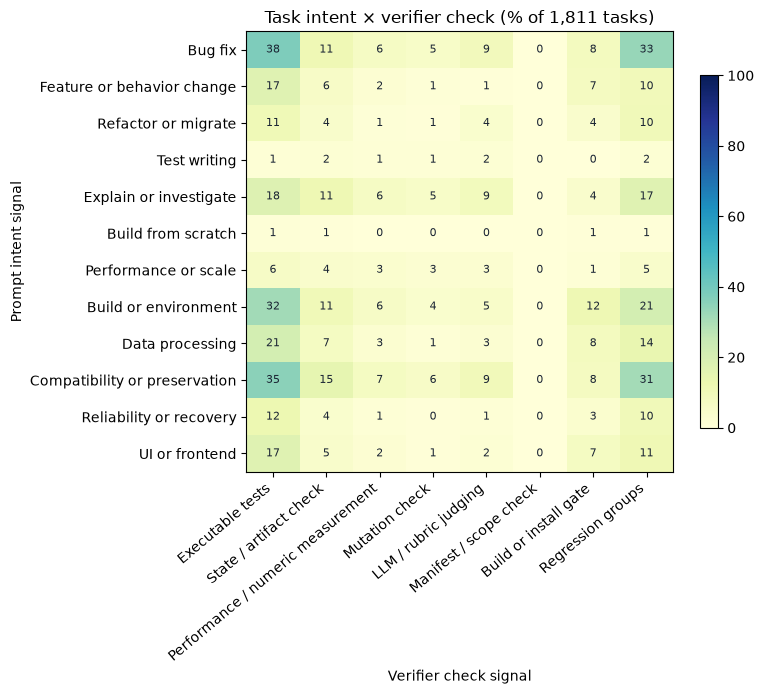

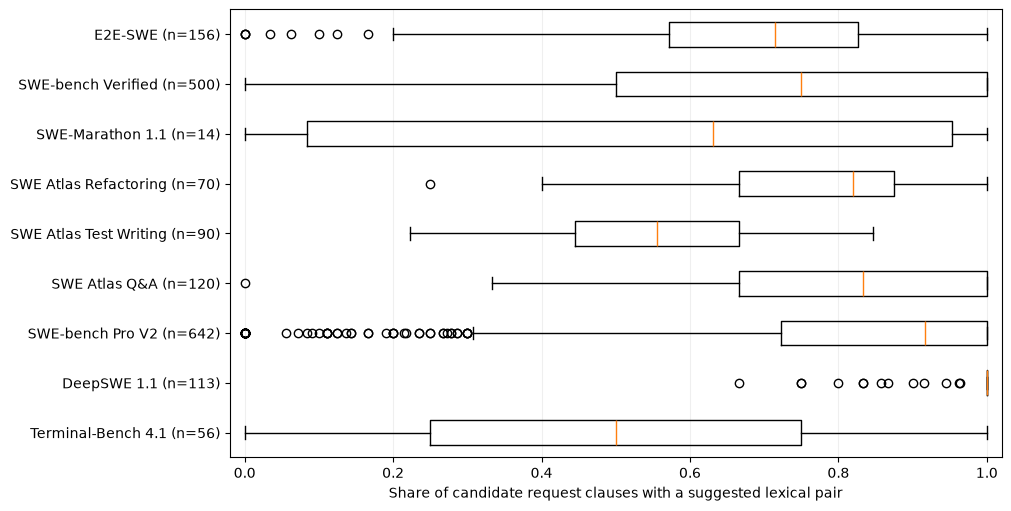

In [11]:
ANALYZE_BENCHMARK = None   # Example: "SWE Atlas Test Writing"
cross_input = (main_features if ANALYZE_BENCHMARK is None
               else main_features.loc[main_features["benchmark"].eq(ANALYZE_BENCHMARK)])
assert len(cross_input) > 0, "Choose a benchmark in main_order or None."
cooccurrence = pd.DataFrame(
    {
        check: [
            sum(intent in intents and check in checks
                for intents, checks in zip(cross_input["intents"], cross_input["check_signals"]))
            for intent in INTENTS
        ] for check in CHECK_RULES
    },
    index=list(INTENTS),
)
heatmap(cooccurrence.div(len(cross_input)).mul(100),
        f"Task intent × verifier check (% of {len(cross_input):,} tasks)",
        "Verifier check signal", ylabel="Prompt intent signal", cmap="YlGnBu")

fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
by_benchmark_box(ax, "pair_rate", "Share of candidate request clauses with a suggested lexical pair")
ax.set_xlim(-0.02, 1.02)
plt.show()

### Task and grading drilldown

Set a benchmark and task ID below. Use the displayed task ID list to pick another record. The inspector returns the original prompt and supplement, extracted request clauses, file references, verifier evidence, rubric criteria, and ranked clause-to-grading links. Increase the display limits or filter the returned tables to explore the rest of a task.

In [12]:
BENCHMARK = "SWE Atlas Test Writing"
TASK_ID = None  # None selects the first task in this benchmark. Paste a task ID here to change it.
available_ids = task_features.loc[BENCHMARK].index.tolist()
chosen_id = TASK_ID or available_ids[0]
record = inspect_task(task_evidence, BENCHMARK, chosen_id)
print(f"{BENCHMARK} | {chosen_id}")
print("First available IDs:", ", ".join(available_ids[:10]))
print("Prompt intent signals:", ", ".join(record["intent_labels"]) or "none observed")
display(pd.Series({
    "Workspace boundary": record["boundary"]["boundary"],
    "Boundary source": record["boundary"]["basis"],
    "Declared artifacts": record["boundary"]["declared_artifacts"],
    "Tests build definition": record["boundary"]["tests_build_definition"],
    "Atlas Q&A rubric comparison": record["rubric_variant"],
    "Grading rule": record["grading_rule"]["decision_rule"],
    "Rule basis": record["grading_rule"]["rule_basis"],
    "Rule source": record["grading_rule"]["rule_source"],
    "Declared test cases": record["grading_rule"]["declared_test_case_count"],
    "Published grade settings": record["grading_rule"]["task_grade_settings"] or "not supplied",
    "Reward references": record["grading_rule"]["reward_channels"] or "not observed",
    "Publisher task note": record["publisher_task_notes"] or "not supplied",
    "Prompt paths": ", ".join(record["deliverables"]["paths"]) or "none observed",
}))
if record["checks"]:
    display(pd.Series(record["checks"], name="Check evidence"))
for name, limit in (
    ("requests", 12), ("reward_evidence", 12), ("rubric", 8), ("alternate_rubric", 8), ("grading_units", 12),
    ("lexical_pairs", 10), ("files", 10),
):
    table = record[name]
    print(f"{name.replace('_', ' ').title()} ({len(table)} records)")
    if not table.empty:
        display(table.head(limit))

# To inspect full source text: print(record["prompt"])

SWE Atlas Test Writing | tw-6902ef3ab97fe23e2ad271ee
First available IDs: tw-6902ef3ab97fe23e2ad271ee, tw-6902ef3ab97fe23e2ad271f1, tw-6902ef3ab97fe23e2ad271f3, tw-6902ef3ab97fe23e2ad271f5, tw-6902ef3ab97fe23e2ad271f6, tw-6902ef3ab97fe23e2ad271f8, tw-6902ef3ab97fe23e2ad271f9, tw-6902ef3ab97fe23e2ad271fa, tw-6902ef3ab97fe23e2ad271fe, tw-6902ef3ab97fe23e2ad271ff
Prompt intent signals: Bug fix, Explain or investigate, Build or environment, Compatibility or preservation


Workspace boundary                                               Shared verifier
Boundary source                Harbor default when the task omits an environm...
Declared artifacts                                                          None
Tests build definition                                                     False
Atlas Q&A rubric comparison                                                 None
Grading rule                   Check the manifest, execute mutation checks, a...
Rule basis                                          Published benchmark protocol
Rule source                       https://labs.scale.com/leaderboard/sweatlas-tw
Declared test cases                                                         None
Published grade settings                                            not supplied
Reward references              {'reward.txt': 'test.sh:47', 'reward.json': 't...
Publisher task note                                                 not supplied
Prompt paths                

LLM / rubric judging                 Task rubric criteria are available
Regression groups                                compare_test_runs.py:6
Executable tests                                  evaluate_tests.py:125
State / artifact check                            evaluate_tests.py:142
Performance / numeric measurement                 evaluate_tests.py:444
Mutation check                                      parse_script.py:179
Name: Check evidence, dtype: str

Requests (9 records)


,origin,line,role,section,text
0,prompt,7,Action request,,Create 5 separate test cases covering:
1,prompt,16,Explicit requirement,,Your tests MUST be runnable using the followin...
2,prompt,109,Question,Run them all together,Can you help me write comprehensive tests for ...
3,prompt,115,Explicit requirement,Run them all together,"Identify key behaviors, edge cases, and error ..."
4,prompt,116,Action request,Run them all together,Write comprehensive tests including unit tests...
5,prompt,117,Explicit requirement,Run them all together,Run your tests using the provided run_script t...
6,prompt,132,Prohibition,Run them all together,"List every test file you created or modified, ..."
7,prompt,133,Action request,Run them all together,Use the appropriate naming convention for the ...
8,prompt,139,Prohibition,Run them all together,Work only from the repository and environment ...


Reward Evidence (15 records)


... (5 outputs left out)

Lexical Pairs (3 records)


,origin,line,role,section,text,score,shared_terms,unit_kind,unit_text,unit_source
0,prompt,16,Explicit requirement,,Your tests MUST be runnable using the followin...,0.225,all,Rubric,3.1: All tests use Jest framework with describ...,rubrics.json
1,prompt,115,Explicit requirement,Run them all together,"Identify key behaviors, edge cases, and error ...",0.189,key,Rubric,1.1: Tests that keyBy returns an object keyed ...,rubrics.json
2,prompt,132,Prohibition,Run them all together,"List every test file you created or modified, ...",0.176,names,Rubric,1.3: Tests that keyBy returns own properties w...,rubrics.json


Files (14 records)


,path,sha,bytes,selected,url
0,compare_test_runs.py,016cd3e0e7ef748a0d551443cdd04ff93930391b,5107,True,https://github.com/scaleapi/SWE-Atlas/blob/b3c...
1,evaluate_tests.py,35163735480cbf79b2be6845f80ef65627a3501e,49796,True,https://github.com/scaleapi/SWE-Atlas/blob/b3c...
2,judge_client.py,687afd3d291a9db2ca19e6ffb556b1272b1997eb,14818,True,https://github.com/scaleapi/SWE-Atlas/blob/b3c...
3,manifest_system_prompt.txt,8f5d091aa47da316dae70873f0ceb90264688afb,4134,False,https://github.com/scaleapi/SWE-Atlas/blob/b3c...
4,manifest_user_prompt_template.txt,12d5d7e213fb024ca5ec2a591cc848a7fd11f084,221,False,https://github.com/scaleapi/SWE-Atlas/blob/b3c...
5,parse_script.py,7f902636726746c70a99774a7e8143a673a941ec,14038,True,https://github.com/scaleapi/SWE-Atlas/blob/b3c...
6,prompt.txt,28fcac7661e85b68f643ff71eb56b959e183199b,575,False,https://github.com/scaleapi/SWE-Atlas/blob/b3c...
7,rubrics.json,fdfc3921f30a27c4ec8097afdd0b84b90ab20e8b,3437,True,https://github.com/scaleapi/SWE-Atlas/blob/b3c...
8,rubrics_system_prompt.txt,69f42adf8c02bef49a41508c8317e0d388657eea,4190,True,https://github.com/scaleapi/SWE-Atlas/blob/b3c...
9,rubrics_user_prompt_template.txt,0a1b4f5fbaef52186c455e2195d3969c1c5de133,109,True,https://github.com/scaleapi/SWE-Atlas/blob/b3c...


## 7. Follow-up questions

Each chart states whether it shows title or prompt signals, source-authored difficulty, a final run disposition, or an individual gate result. A task passing or failing does not reveal which of several checks caused the outcome.

### 7.1 Why does “written answer / report” dominate?

The original signal used a broad word list, including *answer*, *report*, *describe*, and *explain*, across all clauses. It picks up bug reports, existing program output, and background prose. SWE Atlas Q&A also genuinely asks for written answers. The stricter rule requires an explicit submission cue or a named report file. It is still a heuristic, and the table keeps the known Q&A track separate.

,tasks,original_rule,explicit_candidate,known_qa_track
benchmark,,,,
Terminal-Bench 4.1,66,23,3,0
DeepSWE 1.1,113,11,0,0
SWE-bench Pro V2,642,123,0,0
SWE Atlas Q&A,124,44,0,124
SWE Atlas Test Writing,90,90,0,0
SWE Atlas Refactoring,70,70,0,0
SWE-Marathon 1.1,20,4,0,0
SWE-bench Verified,500,130,0,0
E2E-SWE,186,77,0,0


broad_terms
report      229
answer      202
describe    153
document    114
explain      35
write up      1
Name: Tasks with term, dtype: int64

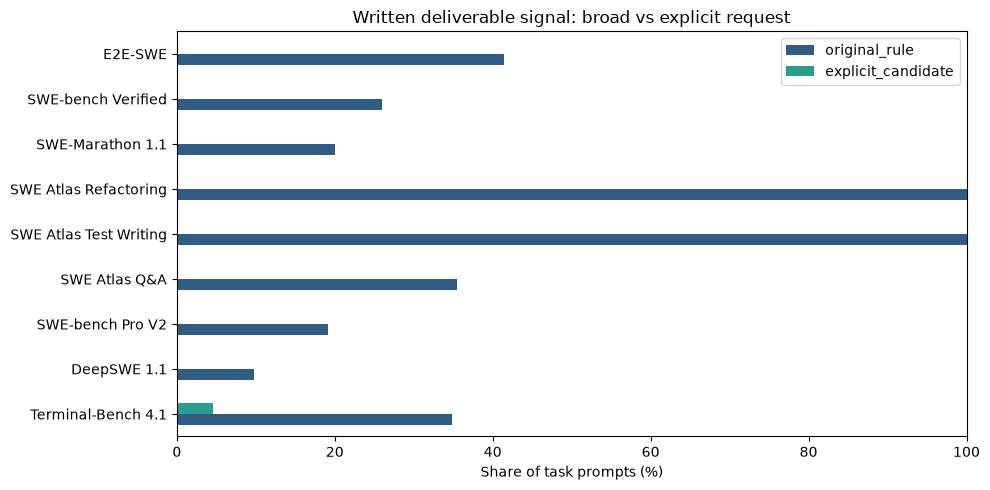

In [13]:
from benchmark_followup import (
    IMPLEMENTATIONS, code_examples, comparison_by_check, deliverable_audit,
    difficulty_by_signal, paired_regression_gates, read_atlas_votes, read_difficulty, read_outcomes,
    read_pro_test_reports,
)

audit = deliverable_audit(task_evidence)
main_audit = audit.loc[audit["benchmark"].isin(main_order)]
audit_summary = main_audit.groupby("benchmark", sort=False).agg(
    tasks=("task_id", "size"), original_rule=("broad", "sum"),
    explicit_candidate=("strict", "sum"), known_qa_track=("atlas_answer_track", "sum"),
).reindex(main_order)
display(audit_summary)
display(main_audit.explode("broad_terms")["broad_terms"].value_counts().rename("Tasks with term"))

audit_percent = audit_summary[["original_rule", "explicit_candidate"]].div(audit_summary["tasks"], axis=0).mul(100)
ax = audit_percent.plot.barh(figsize=(10, 5), color=["#315d85", "#2a9d8f"])
ax.set(xlabel="Share of task prompts (%)", ylabel="", xlim=(0, 100), title="Written deliverable signal: broad vs explicit request")
ax.figure.tight_layout()
plt.show()

### 7.2 Intent and verifier signals vs perceived difficulty

Select a benchmark and difficulty scale below. SWE-bench Verified stores fix-time bands, SWE Atlas Refactoring and SWE-Marathon have author difficulty labels, and Terminal-Bench and Marathon expose expert time estimates. SWE-bench Pro V2 Hard-51 is a publisher cohort selected using observed model difficulty, so it is not treated as a human estimate. Unlabeled tasks are not assigned a difficulty from prompt length.

[SWE-bench Verified annotations](https://openai.com/index/introducing-swe-bench-verified/) · [SWE-bench Pro V2 cohort definition](https://labs.scale.com/blog/swe-bench-pro-v2)

labeled_tasks
benchmark             scale                                         
SWE Atlas Refactoring Author difficulty                           70
SWE-Marathon 1.1      Author difficulty                           20
                      Expert estimated hours                      20
SWE-bench Pro V2      Publisher model-selected cohort            642
SWE-bench Verified    Author fix-time band                       500
Terminal-Bench 4.0    Expert estimated hours                      66
Terminal-Bench 4.1    Expert estimated hours                      66

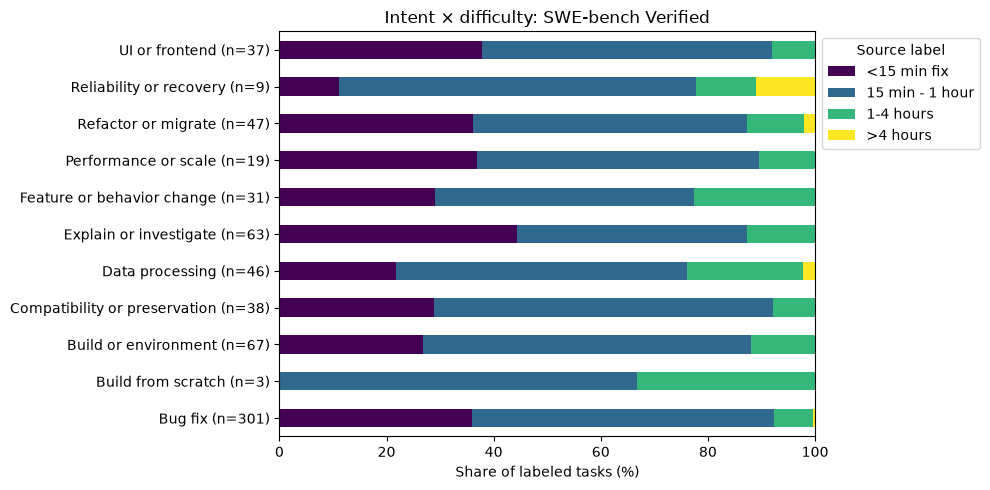

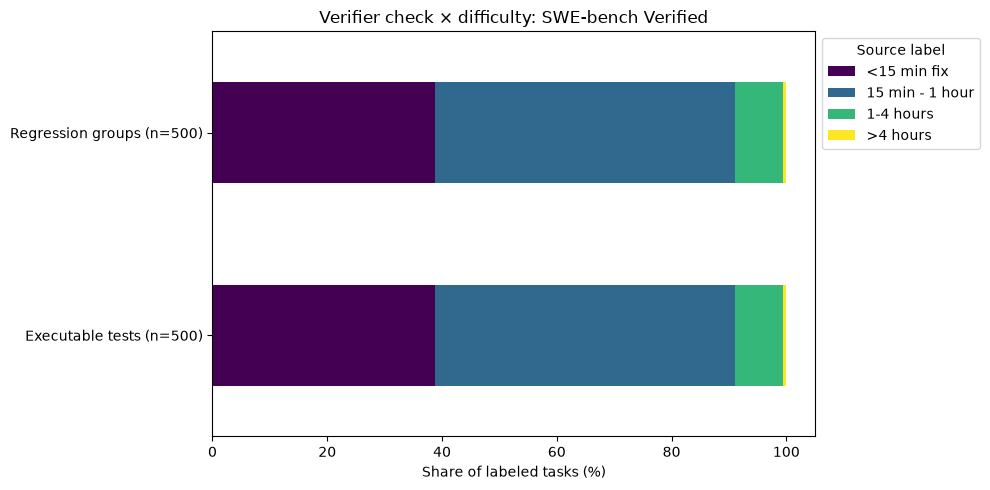

In [14]:
difficulty = read_difficulty(SOURCES, RAW)
difficulty_coverage = difficulty.groupby(["benchmark", "scale"])["task_id"].nunique().rename("labeled_tasks")
display(difficulty_coverage.to_frame())

intent_difficulty = difficulty_by_signal(difficulty, feature_scope, "intents")
check_difficulty = difficulty_by_signal(difficulty, feature_scope, "check_signals")

DIFF_BENCHMARK = "SWE-bench Verified"
DIFF_SCALE = "Author fix-time band"

def plot_difficulty_map(table, title):
    selected = table.loc[table["benchmark"].eq(DIFF_BENCHMARK) & table["scale"].eq(DIFF_SCALE)]
    selected = selected.loc[selected["group"].eq("Detected")]
    if selected.empty:
        print(f"No data for {DIFF_BENCHMARK} / {DIFF_SCALE}. See coverage above.")
        return
    denominators = selected.groupby("signal")["group_n"].first()
    if DIFF_SCALE == "Expert estimated hours":
        medians = selected.groupby("signal")["median_estimated_hours"].first()
        ax = medians.sort_values().plot.barh(figsize=(9, 5), color="#315d85")
        ax.set(xlabel="Median estimated hours", title=title)
        display(pd.concat([medians, denominators], axis=1))
    else:
        shares = selected.pivot(index="signal", columns="label", values="share").fillna(0)
        label_order = difficulty.loc[difficulty["scale"].eq(DIFF_SCALE), ["label", "value"]].drop_duplicates()
        label_order = label_order.sort_values("value")["label"]
        shares = shares.reindex(columns=[label for label in label_order if label in shares])
        shares.index = [f"{label} (n={denominators[label]})" for label in shares.index]
        ax = shares.mul(100).plot.barh(stacked=True, figsize=(10, 5), cmap="viridis")
        ax.set(xlabel="Share of labeled tasks (%)", title=title)
        ax.legend(loc="upper left", bbox_to_anchor=(1, 1), title="Source label")
    ax.figure.tight_layout()
    plt.show()

plot_difficulty_map(intent_difficulty, f"Intent × difficulty: {DIFF_BENCHMARK}")
plot_difficulty_map(check_difficulty, f"Verifier check × difficulty: {DIFF_BENCHMARK}")

### 7.3 Which published reward files or results are available?

Reward files belong to trials. The same task has different results across models, harnesses, and attempts. This fetch keeps the DeepSWE public trial index plus one original reward JSON per task for each of two complete configurations. It also caches Terminal-Bench public trial receipts for six leaderboard rows per version, reports from eleven SWE-bench Verified submissions, nine publisher Pro V1 result maps plus original test reports for one configuration, all published SWE-Marathon v1.1 dashboard receipts, and an older independent SWE Atlas Q&A run with verifier logs. The Q&A run uses an older judge and is separate from Atlas v1.1.

Terminal-Bench raw trial downloads require Harbor authentication in this session; the public receipts expose final rewards. SWE-Marathon’s documented raw-log bucket returned HTTP 403 without access; the publisher dashboard provides per-trial outcomes and partial scores. I could not locate a downloadable task outcome archive for SWE-bench Pro V2, SWE Atlas Test Writing/Refactoring, or E2E-SWE in the checked public sources. Their task definitions and grading evidence remain available above. The coverage table distinguishes missing from failed.

[DeepSWE trials](https://deepswe.datacurve.ai/data/v1.1/trials) · [Terminal-Bench 4.1 leaderboard](https://hub.harborframework.com/datasets/terminal-bench/terminal-bench/5?tab=leaderboard) · [Verified submissions](https://github.com/SWE-bench/experiments/tree/main/evaluation/verified) · [Pro V1 results](https://github.com/scaleapi/SWE-bench_Pro-os/tree/main/traj) · [Independent Q&A run](https://github.com/PhillipChaffee/big-pickle-swe-atlas) · [SWE-Marathon dashboard](https://www.swe-marathon.org/) · [SWE-Marathon logs access](https://github.com/abundant-ai/swe-marathon#downloading-logs)

,corpus_tasks,tasks_with_outcome,scored_trials,configs,tasks_missing_scored_outcomes
benchmark,,,,,
Terminal-Bench 4.1,66,66,1980,6,0
DeepSWE 1.1,113,113,31456,70,0
SWE-bench Pro V2,642,0,0,0,642
SWE Atlas Q&A,124,124,124,1,0
SWE Atlas Test Writing,90,0,0,0,90
SWE Atlas Refactoring,70,0,0,0,70
SWE-Marathon 1.1,20,20,7313,46,0
SWE-bench Verified,500,500,5500,11,0
E2E-SWE,186,0,0,0,186


,reward,f2p_total,f2p_passed,p2p_total,p2p_passed,f2p,p2p,partial
Raw reward JSON fields present,,,,,,,,
mini_swe_agent_claude_sonnet_5_high,113,113,113,113,113,113,113,113
mini_swe_agent_gpt_5_6_sol_medium,113,113,113,113,113,113,113,113


,files,distinct_tasks,binary_reward_mean,diagnostic_partial_mean
config,,,,
mini_swe_agent_claude_sonnet_5_high,113,113,0.451,0.957
mini_swe_agent_gpt_5_6_sol_medium,113,113,0.628,0.983


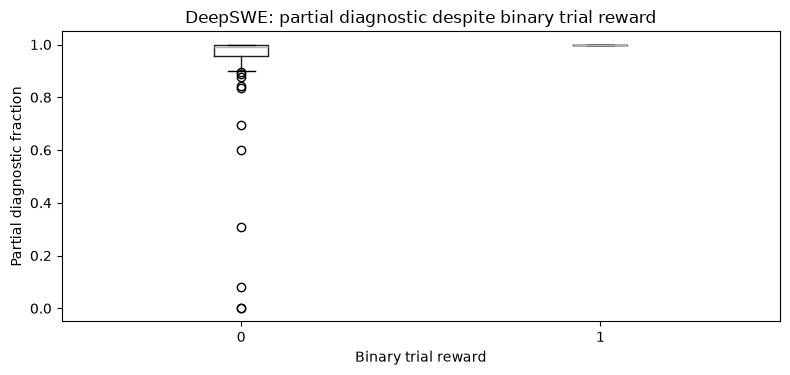

In [15]:
OUTCOME_ROOT = RAW / "outcomes"
published_outcomes, raw_rewards = read_outcomes(OUTCOME_ROOT)
pro_reports = read_pro_test_reports(OUTCOME_ROOT, RAW)
if not pro_reports.empty:
    published_outcomes = pd.concat([published_outcomes, pro_reports], ignore_index=True)
outcomes = published_outcomes.merge(
    feature_scope[["benchmark", "task_id"]], on=["benchmark", "task_id"], how="inner", validate="many_to_one",
)
scored = outcomes.loc[outcomes["pass"].notna()].copy()
scored_coverage = scored.groupby("benchmark").agg(
    tasks_with_outcome=("task_id", "nunique"), scored_trials=("trial", "size"), configs=("config", "nunique")
)
size_coverage = feature_scope.groupby("benchmark", sort=False)["task_id"].size().rename("corpus_tasks")
outcome_coverage = size_coverage.to_frame().join(scored_coverage).fillna(0).astype(int)
outcome_coverage["tasks_missing_scored_outcomes"] = outcome_coverage["corpus_tasks"] - outcome_coverage["tasks_with_outcome"]
display(outcome_coverage)

reward_fields = [key for key in ("reward", "f2p_total", "f2p_passed", "p2p_total", "p2p_passed", "f2p", "p2p", "partial")
                 if key in raw_rewards]
display(raw_rewards.groupby("config")[reward_fields].count().rename_axis("Raw reward JSON fields present"))
sample_reward = raw_rewards.merge(
    outcomes.loc[outcomes["benchmark"].eq("DeepSWE 1.1"), ["config", "trial", "task_id"]],
    on=["config", "trial"], validate="one_to_one",
)
display(sample_reward.groupby("config").agg(
    files=("path", "size"), distinct_tasks=("task_id", "nunique"),
    binary_reward_mean=("reward", "mean"), diagnostic_partial_mean=("partial", "mean"),
).round(3))

ax = sample_reward.boxplot(column="partial", by="reward", grid=False, figsize=(8, 4))
ax.set(xlabel="Binary trial reward", ylabel="Partial diagnostic fraction",
       title="DeepSWE: partial diagnostic despite binary trial reward")
ax.figure.suptitle("")
ax.figure.tight_layout()
plt.show()

### 7.4 Which check was harder to pass?

The left chart is a descriptive task-level comparison for one model/harness configuration. It compares final pass rates for tasks with and without a detected signal, weighting tasks equally. It cannot attribute a failure to that check. Rows need at least five scored tasks on each side. The right chart compares the fix and regression gates directly on the same DeepSWE trials with both nonempty groups and published counts.

Scale’s published Test Writing breakdown reports that mandatory rubrics were the biggest failure mode in its evaluated sample. Its stage results and the DeepSWE regression comparison describe different checks and experiments. [SWE Atlas Test Writing breakdown](https://labs.scale.com/leaderboard/sweatlas-tw#analysis)

Available configurations: Copilot Fusion / GitHub Copilot / max [9ab09ca7] | Fable 5.2 / Claude Code / max [a8c62ada] | GPT-6.2 Astra / Codex / max [2ee86a5a] | Gemini 4 Carbon / Antigravity CLI / high [11495d14] | Opus 5.5 / Claude Code / max [24f711aa] | Sonnet 5.5 / Claude Code / max [cf669033]


,signal,detected_tasks,other_tasks,detected_pass_rate,other_pass_rate,delta_pp
0,Executable tests,27,39,0.733,0.697,3.590
1,State / artifact check,25,41,0.752,0.688,6.420
6,Build or install gate,11,55,0.800,0.695,10.545
2,Performance / numeric measurement,33,33,0.770,0.655,11.515
3,Mutation check,2,64,0.700,0.712,NaN
4,LLM / rubric judging,0,66,NaN,0.712,NaN
5,Manifest / scope check,0,66,NaN,0.712,NaN
7,Regression groups,0,66,NaN,0.712,NaN


Pro V1 paired test-report results


,n,tasks,fix_gate,regression_gate,trial_pass
config,,,,,
claude-45haiku-10222025,357,357,0.507,0.916,0.493


,n,tasks,fix_gate,regression_gate,trial_pass
config,,,,,
mini_swe_agent_claude_fable_5_high,430,113,0.698,0.951,0.686
mini_swe_agent_claude_fable_5_low,433,113,0.621,0.949,0.596
mini_swe_agent_claude_fable_5_max,436,113,0.713,0.931,0.697
mini_swe_agent_claude_fable_5_medium,436,113,0.672,0.961,0.654
mini_swe_agent_claude_fable_5_xhigh,452,113,0.719,0.951,0.699
...,...,...,...,...,...
mini_swe_agent_kimi_k2_7_code_default,452,113,0.334,0.887,0.305
mini_swe_agent_kimi_k3_max,451,113,0.710,0.951,0.685
mini_swe_agent_muse_spark_1_1_xhigh,452,113,0.586,0.892,0.533


Fix gate had a lower pass rate in 65 of 65 configs on 29,196 paired DeepSWE trials.


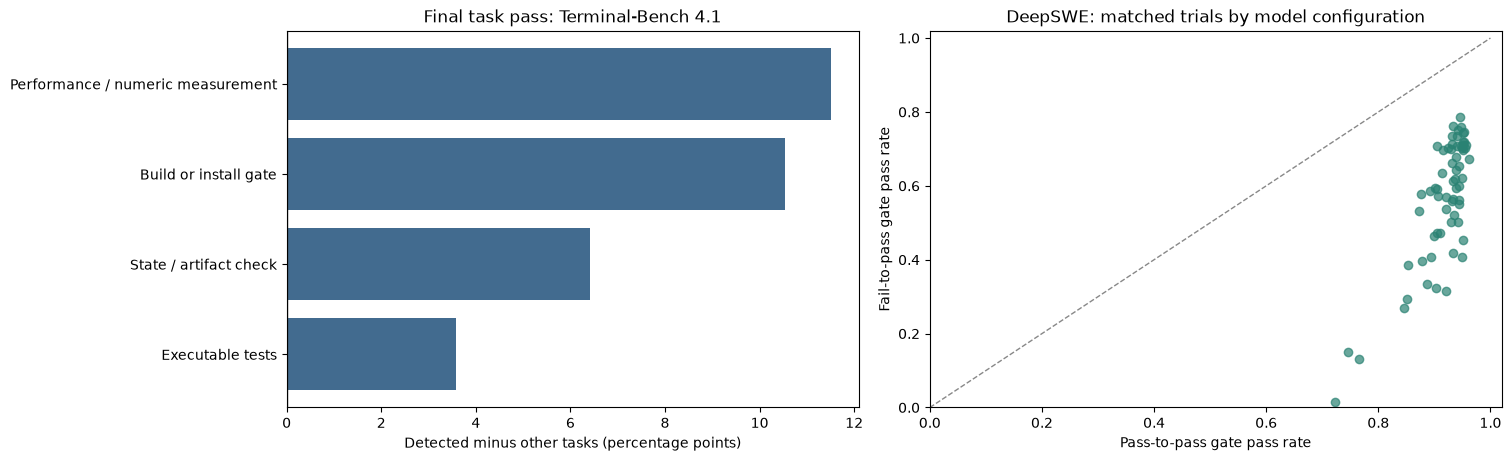

In [16]:
RESULT_BENCHMARK = "Terminal-Bench 4.1"
available_configs = sorted(scored.loc[scored["benchmark"].eq(RESULT_BENCHMARK), "config"].unique())
RESULT_CONFIG = available_configs[0]  # Or paste a label from the list below.
print("Available configurations:", " | ".join(available_configs))
signal_outcomes = comparison_by_check(outcomes, feature_scope, RESULT_BENCHMARK, RESULT_CONFIG)
display(signal_outcomes.round(3))
gate_rates = paired_regression_gates(outcomes)
pro_gate_rates = paired_regression_gates(outcomes, "SWE-bench Pro V1")
if not pro_gate_rates.empty:
    print("Pro V1 paired test-report results")
    display(pro_gate_rates.round(3))
display(gate_rates[["n", "tasks", "fix_gate", "regression_gate", "trial_pass"]].round(3))
print(f"Fix gate had a lower pass rate in {gate_rates['fix_gate'].lt(gate_rates['regression_gate']).sum()} of "
      f"{len(gate_rates)} configs on {gate_rates['n'].sum():,} paired DeepSWE trials.")

fig, (axl, axr) = plt.subplots(1, 2, figsize=(15, 4.5), layout="constrained")
lower = signal_outcomes.dropna(subset=["delta_pp"])
if not lower.empty:
    axl.barh(lower["signal"], lower["delta_pp"], color="#426b8f")
axl.axvline(0, color="#444", linewidth=1)
axl.set(xlabel="Detected minus other tasks (percentage points)", title=f"Final task pass: {RESULT_BENCHMARK}")
axr.scatter(gate_rates["regression_gate"], gate_rates["fix_gate"], alpha=.7, color="#2a8273")
axr.plot([0, 1], [0, 1], "--", color="#888", linewidth=1)
axr.set(xlabel="Pass-to-pass gate pass rate", ylabel="Fail-to-pass gate pass rate",
        title="DeepSWE: matched trials by model configuration", xlim=(0, 1.02), ylim=(0, 1.02))
plt.show()

### 7.5 How the check signals are implemented

The table explains the common control flow; select one signal to see examples across benchmark sources. A match is a location to verify manually. Shared patterns include running a test runner then parsing its output, comparing a candidate artifact against a reference, and gating a final verdict on several checks. The concrete tests, thresholds, and output schemas remain task-specific.

In [17]:
display(pd.Series(IMPLEMENTATIONS, name="Common implementation pattern").to_frame())
implementation_examples = code_examples(task_evidence)
regression_source = pd.DataFrame([
    {"check": "Regression groups", "benchmark": "SWE-bench Pro V1", "source_location": "swe_bench_pro_eval.py: passed_tests / f2p / p2p",
     "source_url": "https://github.com/scaleapi/SWE-bench_Pro-os/blob/66f92766bba642462d4bbe5479e83f91f9211862/swe_bench_pro_eval.py"},
    {"check": "Regression groups", "benchmark": "DeepSWE 1.1", "source_location": "grader.py: binary reward and F2P/P2P counts",
     "source_url": "https://github.com/datacurve-ai/deep-swe/tree/435ee89ec2f2e2289f33b0da4f992f0b7b7266b9/tasks"},
])
implementation_examples = pd.concat([implementation_examples, regression_source], ignore_index=True)
EXAMPLE_SIGNAL = "Executable tests"  # Choose another label from IMPLEMENTATIONS.
display(implementation_examples.loc[implementation_examples["check"].eq(EXAMPLE_SIGNAL)]
        .drop(columns=["check"]).reset_index(drop=True))

,Common implementation pattern
Executable tests,Run the language's test runner on the submitte...
State / artifact check,"Read the produced file, return value, or final..."
Performance / numeric measurement,Collect a metric and compare it with a thresho...
Mutation check,Run the candidate tests against the original i...
LLM / rubric judging,Evaluate individual criteria against the answe...
Manifest / scope check,Read the candidate's manifest or diff and dete...
Build or install gate,Run an install or build step in a defined work...
Regression groups,Track named fix and regression tests separatel...


,benchmark,task_id,source_location,source_url,value
0,Terminal-Bench 4.1,batched-eval-parity,conftest.py:3,https://github.com/harbor-framework/terminal-b...,Static signal; inspect source to confirm
1,DeepSWE 1.1,abs-module-cache-flags,test.sh:32,,Static signal; inspect source to confirm
2,SWE Atlas Test Writing,tw-6902ef3ab97fe23e2ad271ee,evaluate_tests.py:125,https://github.com/scaleapi/SWE-Atlas/blob/b3c...,Static signal; inspect source to confirm
3,SWE Atlas Refactoring,rf-69391d8d1ce51c407be1e531,master_validator_script.sh:186,https://github.com/scaleapi/SWE-Atlas/blob/b3c...,Static signal; inspect source to confirm
4,SWE-Marathon 1.1,biofabric-rust-rewrite,test.sh:119,https://github.com/abundant-ai/swe-marathon/bl...,Static signal; inspect source to confirm
5,E2E-SWE,all-repos,test.sh:27,https://github.com/facebookresearch/E2E-SWE/bl...,Static signal; inspect source to confirm
6,Terminal-Bench 4.0,atrx-vep-crispr,Dockerfile:62,https://github.com/harbor-framework/terminal-b...,Static signal; inspect source to confirm


### 7.6 SWE Atlas rubric graders

- **Codebase Q&A:** the judge scores the submitted answer criterion by criterion. In the pinned GitHub grader, every declared must-have needs a passing verdict. A negative criterion is normalized to the effective verdict before aggregation.
- **Test Writing:** manifest, mutation and mandatory rubric checks combine into the final pass. The mutation stage checks that submitted tests pass on the original code and detect a specified broken variant.
- **Refactoring:** executable checks test behavior preservation and the rubric checks the requested restructuring, maintainability, and cleanup. Mandatory items gate the overall result; nice-to-have items can still appear in diagnostic scores.

Scale says Atlas v1.1 uses a three-vote majority with GPT‑6.1 Sol. The downloaded Q&A logs show raw and effective criterion judgments from a separate older run. They are useful for understanding the schema, not for evaluating the current judge.

[SWE Atlas paper](https://labs.scale.com/papers/sweatlas) · [v1.1 leaderboard notes](https://labs.scale.com/leaderboard/swe-atlas) · [Pinned verifier code](https://github.com/scaleapi/SWE-Atlas/tree/b3cdddf44414c0ccca50c6e89fe978bb4d844d26/data)

importance,must have,nice to have
benchmark,,
SWE Atlas Q&A,1306,0
SWE Atlas Refactoring,1112,32
SWE Atlas Test Writing,772,755


scored_criteria  \
importance_in_bundle type_in_bundle                           
must have            negative hli verifier               86   
                     positive hli verifier             1211   

                                            effective_pass_rate  \
importance_in_bundle type_in_bundle                               
must have            negative hli verifier                0.953   
                     positive hli verifier                0.921   

                                            polarity_flips  
importance_in_bundle type_in_bundle                         
must have            negative hli verifier              86  
                     positive hli verifier               0

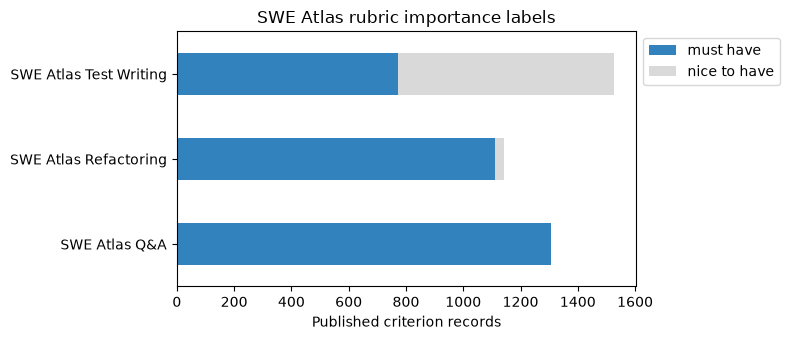

In [18]:
rubric_rows = [
    {"benchmark": bench, "task_id": task_id, "importance": row["importance"] or "unspecified",
     "polarity/type": row["type"] or "unspecified"}
    for (bench, task_id), item in task_evidence.items()
    for row in item["rubric"]
]
rubric_catalog = pd.DataFrame(rubric_rows)
rubric_counts = pd.crosstab(rubric_catalog["benchmark"], rubric_catalog["importance"])
display(rubric_counts)
qa_csv = RAW / "swe-atlas-qna/data/test/cae_qna_124_public.csv"
legacy_votes = read_atlas_votes(OUTCOME_ROOT, qa_csv)
if not legacy_votes.empty:
    votes = legacy_votes.loc[legacy_votes["bundle_id_matched"]].copy()
    votes["flipped"] = votes["raw"].ne(votes["effective"])
    vote_summary = votes.groupby(["importance_in_bundle", "type_in_bundle"], dropna=False).agg(
        scored_criteria=("criterion_id", "size"), effective_pass_rate=("effective", "mean"),
        polarity_flips=("flipped", "sum"),
    )
    display(vote_summary.round(3))

ax = rubric_counts.plot.barh(stacked=True, figsize=(8, 3.5), colormap="tab20c")
ax.set(xlabel="Published criterion records", ylabel="", title="SWE Atlas rubric importance labels")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.figure.tight_layout()
plt.show()

### 7.7 How regression groups work

**Fail-to-pass (F2P)** identifies failing baseline behavior the change should fix. **Pass-to-pass (P2P)** checks behavior that already worked. A typical grader runs the candidate with the hidden tests, parses the test report, and checks that all configured IDs in both groups are in the passed set. A missing or failed required test does not satisfy the gate.

SWE-bench Pro V1 implements a set containment check. DeepSWE uses named test groups and emits separate counts, binary reward, and a partial diagnostic. Its binary rule also requires a nonempty F2P group. A named regression test and a mutation test have different roles: the former guards an existing behavior, the latter checks whether an agent-authored test detects a deliberately broken variant.

[Verified scoring contract](https://openai.com/index/introducing-swe-bench-verified/) · [Pro V1 evaluation code](https://github.com/scaleapi/SWE-bench_Pro-os/blob/66f92766bba642462d4bbe5479e83f91f9211862/swe_bench_pro_eval.py) · [DeepSWE grader and task layout](https://github.com/datacurve-ai/deep-swe)

In [19]:
group_sizes = feature_scope.groupby("benchmark").agg(
    f2p_tasks=("f2p_count", "count"), f2p_median=("f2p_count", "median"),
    p2p_tasks=("p2p_count", "count"), p2p_median=("p2p_count", "median"),
)
display(group_sizes.loc[group_sizes["f2p_tasks"].gt(0)].round(1))

,f2p_tasks,f2p_median,p2p_tasks,p2p_median
benchmark,,,,
DeepSWE 1.1,113,44.0,113,165.0
SWE-bench Pro V1,731,3.0,731,0.0
SWE-bench Pro V2,642,4.0,642,1.0
SWE-bench Verified,500,1.0,500,50.5


### 7.8 Use the task and grading drilldown

1. In the cell below, pick a benchmark and filter by prompt text or a verifier signal. Copy a task ID from the shortlist.
2. In Section 6, paste it into `TASK_ID` and set `BENCHMARK`. Read the request first, then compare its clauses with the grading units and the evidence file.
3. Check that a lexical pair matches the behavior, and read the source or rubric if the wording differs. Missing pairs do not establish a coverage gap.
4. The cell below also shows published run receipts and original DeepSWE reward paths for the selected task where available. Compare within a model, harness, and benchmark version before comparing different tasks.

In [20]:
INSPECT_BENCHMARK = "DeepSWE 1.1"
QUERY = "cache"  # Literal text in the prompt or task ID. Blank matches all.
CHECK = None     # Example: "Regression groups"
INSPECT_ID = None
shortlist = feature_scope.loc[feature_scope["benchmark"].eq(INSPECT_BENCHMARK)].copy()
if CHECK:
    shortlist = shortlist.loc[shortlist["check_signals"].map(lambda labels: CHECK in labels)]
if QUERY and not shortlist.empty:
    keep = shortlist["task_id"].str.contains(QUERY, case=False, regex=False) | shortlist.apply(
        lambda row: QUERY.casefold() in task_evidence[(row["benchmark"], row["task_id"])]["task_prompt"].casefold(),
        axis=1,
    )
    shortlist = shortlist.loc[keep]
display(shortlist[["task_id", "intents", "check_signals", "grading_family", "visible_grading_units"]].head(12))

if INSPECT_ID or not shortlist.empty:
    current_id = INSPECT_ID or shortlist.iloc[0]["task_id"]
    detail = inspect_task(task_evidence, INSPECT_BENCHMARK, current_id)
    print(f"Selected {INSPECT_BENCHMARK}: {current_id}")
    display(detail["requests"].head(6))
    display(detail["lexical_pairs"].head(6))
    results = scored.loc[scored["benchmark"].eq(INSPECT_BENCHMARK) & scored["task_id"].eq(current_id)]
    if not results.empty:
        display(results.groupby(["config", "artifact"]).agg(
            published_scored_trials=("trial", "size"), observed_pass_rate=("pass", "mean"),
        ).round(3).head(12))
    else:
        print("No published scored trials matched this task in the local cache.")
    display(sample_reward.loc[sample_reward["task_id"].eq(current_id) & sample_reward["benchmark"].eq(INSPECT_BENCHMARK),
                              ["config", "reward", "partial", "path"]])

,task_id,intents,check_signals,grading_family,visible_grading_units
66,abs-module-cache-flags,"(Explain or investigate, Build or environment,...","(Regression groups, Executable tests, State / ...",Binary gate + test diagnostics,45
76,bandit-incremental-cache-control,"(Compatibility or preservation,)","(Regression groups, Executable tests, State / ...",Binary gate + test diagnostics,453
81,clack-async-autocomplete-options,"(Reliability or recovery, UI or frontend)","(Regression groups, Executable tests, State / ...",Binary gate + test diagnostics,823
83,cliffy-config-file-parsing,"(Data processing, Compatibility or preservation)","(Regression groups, State / artifact check, Ex...",Binary gate + test diagnostics,489
89,dynamodb-toolbox-lazy-recursive-schemas,"(Data processing,)","(Regression groups, Executable tests, State / ...",Binary gate + test diagnostics,1359
90,effect-sse-httpapi-streaming,"(Data processing, Reliability or recovery)","(Regression groups, Executable tests, State / ...",Binary gate + test diagnostics,143
122,koota-pair-relation-tracking,(),"(Regression groups, Executable tests, State / ...",Binary gate + test diagnostics,265
149,query-persist-restored-query-state,"(Compatibility or preservation,)","(Regression groups, Executable tests, State / ...",Binary gate + test diagnostics,62
173,vulture-persistent-analysis-cache,"(Build from scratch, Build or environment)","(Regression groups, Executable tests, State / ...",Binary gate + test diagnostics,344


Selected DeepSWE 1.1: abs-module-cache-flags


,origin,line,role,section,text
0,prompt,5,Explicit requirement,,Equivalent paths that point to the same module...
1,prompt,30,Prohibition,,Unknown flags before script path do not preven...
2,prompt,32,Action request,,Preserve the public REPL entrypoint signature:...
3,prompt,36,Explicit requirement,,Internal-signature flexibility does not apply ...
4,prompt,37,Action request,,Keep the implementation focused on the behavio...


,origin,line,role,section,text,score,shared_terms,unit_kind,unit_text,unit_source
0,prompt,5,Explicit requirement,,Equivalent paths that point to the same module...,0.419,"cache, paths",Static test name,TestChallengeRequireCacheKeysCanonicalAbsolute...,test.patch:262
1,prompt,30,Prohibition,,Unknown flags before script path do not preven...,0.630,"before, script, unknown",Static test name,TestChallengeBeginReplScriptModeWithUnknownFla...,test.patch:726
2,prompt,32,Action request,,Preserve the public REPL entrypoint signature:...,0.854,"begin, repl, signature",Static test name,TestChallengeBeginReplSignature,test.patch:525
3,prompt,36,Explicit requirement,,Internal-signature flexibility does not apply ...,0.591,signature,Static test name,TestChallengeBeginReplSignature,test.patch:525


,,published_scored_trials,observed_pass_rate
config,artifact,,
mini_swe_agent_claude_fable_5_high,Publisher trial index,4,1.00
mini_swe_agent_claude_fable_5_low,Publisher trial index,4,0.00
mini_swe_agent_claude_fable_5_max,Publisher trial index,4,1.00
mini_swe_agent_claude_fable_5_medium,Publisher trial index,4,0.25
mini_swe_agent_claude_fable_5_xhigh,Publisher trial index,4,1.00
mini_swe_agent_claude_opus_4_8_high,Publisher trial index,4,1.00
mini_swe_agent_claude_opus_4_8_low,Publisher trial index,4,0.75
mini_swe_agent_claude_opus_4_8_max,Publisher trial index,4,1.00
mini_swe_agent_claude_opus_4_8_medium,Publisher trial index,4,0.75


,config,reward,partial,path
0,mini_swe_agent_claude_sonnet_5_high,0,0.695652,deep/files/mini_swe_agent_claude_sonnet_5_high...
113,mini_swe_agent_gpt_5_6_sol_medium,1,1.000000,deep/files/mini_swe_agent_gpt_5_6_sol_medium/a...
